# From casting to aged γ′: janus-kinetics and kawin together

A cast Ni-base alloy is not uniform. The dendrite cores freeze first and lean, the last liquid
between the arms freezes rich in solute, and a homogenization anneal is meant to even that out
before the alloy is aged to precipitate γ′. Where the anneal falls short, the core and the
interdendritic region age differently.

This notebook follows that sequence with two open packages built on pycalphad:

1. casting with back-diffusion in the solid, in
   [janus-kinetics](https://github.com/odinzen/janus-kinetics);
2. the homogenization anneal, in janus-kinetics;
3. γ′ precipitation during ageing at the local compositions, in
   [kawin](https://github.com/materialsgenomefoundation/kawin) (Ury et al., Acta Mater.
   255 (2023) 118988), through janus-kinetics' optional bridge.

The alloy is Ni-5.2Al-14.2Cr (at.%), whose γ′ ageing at 600 °C (873 K) Sudbrack et al. followed
by atom probe (Acta Mater. 54 (2006) 3199). The thermodynamics are the Al-Cr-Ni description of
Dupin, Ansara and Sundman (Calphad 25 (2001) 279), `alcrni.tdb`; the mobilities are those of
Campbell, Boettinger and Kattner (Acta Mater. 50 (2002) 775), which ship with janus-kinetics.
Both packages read the same files, and the last section checks that they then agree.

Install with `pip install "janus-kinetics[kawin] @ git+https://github.com/odinzen/janus-kinetics"`.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
from pycalphad import Database, equilibrium, variables as v

from janus_kinetics import SolutionPhase, TemperatureSchedule
from janus_kinetics import campbell2002_fcc_ni, solve_planar
from janus_kinetics.dendrite_tip import liquidus
from janus_kinetics.kawin_bridge import (
    kawin_history,
    kawin_model,
    kawin_thermodynamics,
    local_compositions,
)
from janus_kinetics.multicomponent_precipitation import NucleationSettings
from janus_kinetics.solidification import (
    equilibrium_start,
    scheil_gulliver,
    segregation_profile,
    solve_solidification_to_end,
)

warnings.filterwarnings("ignore")
db = Database("alcrni.tdb")
comps = ["AL", "CR", "NI"]
alloy = [0.052, 0.142]  # mole fractions of Al and Cr
mobility = campbell2002_fcc_ni()
gamma = SolutionPhase(db, "FCC_A1", comps, mobility_db=mobility)
melt = SolutionPhase(db, "LIQUID", comps, mobilities=False)

## 1. Casting: back-diffusion across a dendrite arm

The primary γ grows from the axis of a cylindrical volume element 25 µm in radius (half of a
50 µm secondary arm spacing) while the melt cools at 10 K/s, with local equilibrium at the
solid/liquid interface and diffusion in the solid. The solid's interdiffusion matrix is taken
once, just below the liquidus. The solver stops when the liquid layer has all but gone
(here with 1.9 % liquid left); that last liquid freezes by the Scheil path, which fills the
outer shell of the arm.

In [2]:
arm = 25e-6  # m, half the secondary arm spacing
t_liq = liquidus(gamma, melt, alloy, 1700.0).temperature
start = equilibrium_start(db, comps, "FCC_A1", "LIQUID", alloy,
                          t_liq - 0.5)
d_solid = gamma.interdiffusion_matrix(start[1], t_liq - 20)
rate, span = 10.0, 150.0  # K/s, K
cooling = TemperatureSchedule([0.0, span / rate],
                              [t_liq - 0.5, t_liq - 0.5 - span])
cast = solve_solidification_to_end(
    db, ["LIQUID", "L12_FCC"], gamma, melt, cooling, span / rate,
    arm, start, step=1.0, solid_diffusivity=d_solid, cells=40,
    dt=0.2 / rate, disordered={"L12_FCC": "FCC_A1"},
    geometry="cylindrical")
bd = cast.back_diffusion
left = 1 - bd.fraction_solid[-1]
print(f"liquidus {t_liq:.1f} K; liquid left {left:.4f} "
      f"at {bd.temperature[-1]:.1f} K")

# the last liquid by Scheil, laid into the outer shell of the arm
last = scheil_gulliver(db, comps, ["LIQUID", "FCC_A1"], bd.liquid[-1],
                       bd.temperature[-1] + 0.5, 0.25,
                       stop_fraction=1e-3, t_min=1300.0)
fs_last, x_last = last.increments()
fs_cells = (bd.solid_faces[-1] / arm) ** 2  # cylinder: by area
edges = np.concatenate([fs_cells, fs_cells[-1] + left * fs_last[1:]])
solid = np.vstack([bd.solid[-1], x_last])
faces, as_cast = segregation_profile(edges, solid, arm, 120,
                                     "cylindrical")
area = np.diff(faces ** 2)
print("mean of the as-cast arm (Al, Cr):",
      np.round(area @ as_cast / area.sum(), 5))

liquidus 1695.9 K; liquid left 0.0189 at 1681.4 K


mean of the as-cast arm (Al, Cr): [0.052 0.142]


## 2. Homogenization at 1200 °C

The as-cast profile is annealed at 1473 K in the same cylinder, now with Campbell's
composition-dependent mobilities. Two anneals are kept for ageing: a short one, 6 minutes,
that leaves part of the segregation, and 2 hours, after which the arm is uniform.

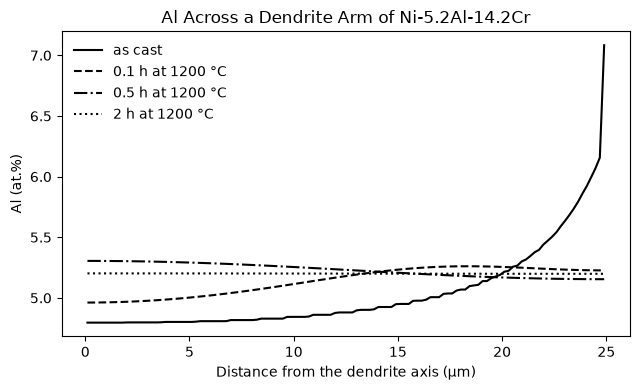

In [3]:
anneal_h = np.array([0.1, 0.5, 2.0])
anneal = solve_planar(faces, as_cast,
                      gamma.interdiffusion_function(1473.0),
                      anneal_h[-1] * 3600, 10.0,
                      save_times=anneal_h * 3600,
                      geometry="cylindrical")
r = anneal.z * 1e6
fig, ax = plt.subplots(figsize=(6.5, 4.0))
styles = ["-", "--", "-.", ":"]
labels = ["as cast"] + [f"{h:g} h at 1200 °C" for h in anneal_h]
for i, (style, label) in enumerate(zip(styles, labels)):
    ax.plot(r, 100 * anneal.x[i, :, 0], "k" + style, label=label)
ax.set_xlabel("Distance from the dendrite axis (µm)")
ax.set_ylabel("Al (at.%)")
ax.set_title("Al Across a Dendrite Arm of Ni-5.2Al-14.2Cr")
ax.legend(frameon=False)
fig.tight_layout()

## 3. Strength inputs for kawin

Each ageing run below carries kawin's strength model, after Ahmadi, Povoden-Karadeniz, Öksüz,
Falahati and Kozeschnik (Comput. Mater. Sci. 91 (2014) 173), which turns the size distribution
into a yield-strength increment from
particle cutting (anti-phase boundary, coherency strain, interfacial area) and Orowan looping,
taking the weaker of the two. The inputs:

- shear modulus and Poisson ratio of γ, the Hill average of the elastic constants of
  Ni-12.69Al (Prikhodko, Carnes, Isaak and Ardell, Scripta Mater. 38 (1997) 67, Table 1),
  interpolated to 873 K between the 850 and 900 K rows;
- Burgers vector a/√2 with the γ lattice parameter 0.3552 nm (Sudbrack et al. 2006);
- the {111} anti-phase boundary energy of binary Ni<sub>3</sub>Al, 175 mJ/m² (Karnthaler,
  Mühlbacher and Rentenberger, Acta Mater. 44 (1996) 547, section 3.3.1);
- the γ/γ′ lattice misfit 0.0006 (Sudbrack et al. 2006) and the interfacial energy,
  22.5 mJ/m², that the nucleation below uses (Sudbrack, Noebe and Seidman 2007);
- the Taylor factor of a randomly oriented fcc polycrystal, 3.06 (Stoller and Zinkle,
  J. Nucl. Mater. 283-287 (2000) 349).

The modulus mismatch term is left out, for want of a shear modulus of γ′ at 873 K. The
elastic constants are of a binary γ and the APB energy of a binary γ′; the Cr in this alloy
shifts both by amounts not measured here. Booth-Morrison et al. (Acta Mater. 56 (2008) 3422)
take 100.9 GPa from the same table as the shear modulus of γ, which is c<sub>44</sub> at 873 K;
the isotropic average used here is lower.

In [4]:
from kawin.precipitation.coupling import (
    APBContribution,
    CoherencyContribution,
    DislocationParameters,
    InterfacialContribution,
    StrengthModel,
)

# Prikhodko et al. Table 1, GPa: rows at 850 and 900 K
c11, c12, c44 = 1e9 * np.array(
    [np.interp(873.0, [850.0, 900.0], row)
     for row in ([214.4, 212.7], [150.9, 149.7], [101.7, 100.0])])
# Voigt and Reuss bounds of a cubic crystal, and their mean (Hill)
g_voigt = (c11 - c12 + 3 * c44) / 5
g_reuss = 5 * (c11 - c12) * c44 / (4 * c44 + 3 * (c11 - c12))
shear = (g_voigt + g_reuss) / 2
bulk = (c11 + 2 * c12) / 3
poisson = (3 * bulk - 2 * shear) / (2 * (3 * bulk + shear))
print(f"c44 {c44 / 1e9:.1f} GPa; Hill average G = {shear / 1e9:.1f} GPa, "
      f"nu = {poisson:.3f}")

dislocations = DislocationParameters(G=shear, b=0.3552e-9 / np.sqrt(2),
                                     nu=poisson)
eps = CoherencyContribution.latticeMisfit(0.0006, dislocations)
mechanisms = [APBContribution(yAPB=0.175),
              CoherencyContribution(eps=eps),
              InterfacialContribution(gamma=0.0225)]
taylor = 3.06  # yield strength over resolved shear stress

c44 100.9 GPa; Hill average G = 63.5 GPa, nu = 0.335


## 4. Ageing at 600 °C in kawin, at the dendrite axis and the arm edge

`kawin_thermodynamics` hands kawin the same database with Campbell's mobilities merged in, and
`kawin_model` builds kawin's precipitation model from janus-kinetics' nucleation settings:
interfacial energy 22.5 mJ/m² and a molar volume from a = 0.3554 nm (Sudbrack, Noebe and
Seidman, Acta Mater. 55 (2007) 119, section 4.1), the γ lattice parameter 0.3552 nm at 873 K
(Sudbrack et al. 2006), and homogeneous nucleation on every lattice site.
Each local composition is aged for 256 h at 873 K.

In [5]:
thermo = kawin_thermodynamics(db, "FCC_A1", ["L12_FCC"], comps,
                              mobility_db=mobility)
settings = NucleationSettings(gamma=0.0225, molar_volume=6.7584e-6,
                              lattice_parameter=0.3552e-9)
spots = {"axis": anneal.z[0], "edge": anneal.z[-1]}
states = {"as cast": 0, "6 min": 1, "2 h": 3}
local = {}
for state, i in states.items():
    xs = local_compositions(anneal.z, anneal.x[i], list(spots.values()))
    for spot, x in zip(spots, xs):
        local[state, spot] = x

age_hours = 256.0
aged, strengths = {}, {}
for key, x in local.items():
    if key[0] == "2 h" and key[1] == "edge":
        continue  # the arm is uniform by then
    model = kawin_model(thermo, "L12_FCC", x, 873.0, settings,
                        ["AL", "CR"])
    strength = StrengthModel(["L12_FCC"], mechanisms, dislocations)
    strength.M = taylor
    model.addCouplingModel(strength)
    model.solve(age_hours * 3600, verbose=False)
    aged[key] = kawin_history(model, strength)
    strengths[key] = strength

def equilibrium_gamma_prime(x, T=873.0):
    # gamma' is the Al-rich one of the two L12_FCC composition sets
    eq = equilibrium(db, comps + ["VA"], ["FCC_A1", "L12_FCC"],
                     {v.T: T, v.P: 101325, v.N: 1,
                      v.X("AL"): x[0], v.X("CR"): x[1]})
    amount = np.ravel(eq.NP.values)
    al = eq.X.values.reshape(amount.size, -1)[:, 0]
    return float(np.nansum(np.where(al > 0.1, amount, 0.0)))


# strength relative to the homogenized alloy at the end of ageing
reference = aged["2 h", "axis"].strength[-1]
print(f"{'state':<9}{'spot':<6}{'Al':>6}{'Cr':>7}{'gamma prime':>13}"
      f"{'at equilibrium':>16}{'radius':>9}{'strength':>10}")
for (state, spot), h in aged.items():
    x = local[state, spot]
    print(f"{state:<9}{spot:<6}{100 * x[0]:6.2f}{100 * x[1]:7.2f}"
          f"{100 * h.volume_fraction[-1]:12.1f}%"
          f"{100 * equilibrium_gamma_prime(x):15.1f}%"
          f"{1e9 * h.mean_radius[-1]:7.2f} nm"
          f"{h.strength[-1] / reference:10.2f}")

state    spot      Al     Cr  gamma prime  at equilibrium   radius  strength
as cast  axis    4.80  13.26         0.1%            4.7%  21.52 nm      0.03
as cast  edge    7.08  17.84        37.1%           38.5%   6.79 nm      0.69


6 min    axis    4.96  13.38         5.7%            6.8%   8.91 nm      0.66
6 min    edge    5.23  14.81        12.5%           13.7%   8.19 nm      1.13
2 h      axis    5.20  14.19        10.6%           11.8%   8.43 nm      1.00


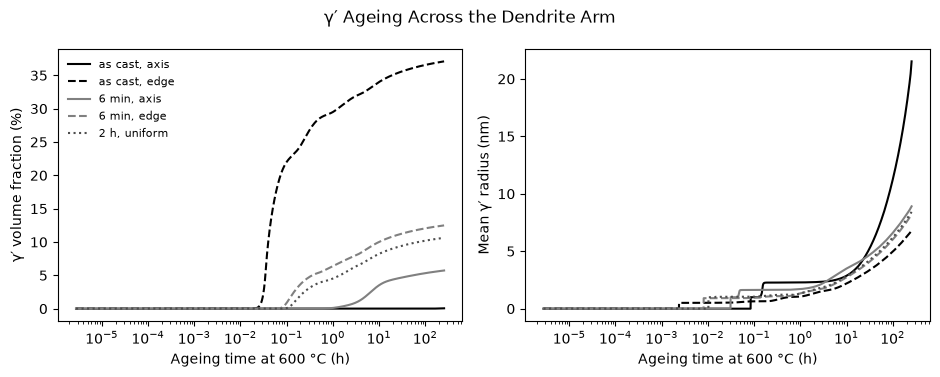

In [6]:
fig, (a, b) = plt.subplots(1, 2, figsize=(9.5, 3.8))
looks = {("as cast", "axis"): ("k", "-"), ("as cast", "edge"): ("k", "--"),
         ("6 min", "axis"): ("0.5", "-"), ("6 min", "edge"): ("0.5", "--"),
         ("2 h", "axis"): ("0.3", ":")}
for key, h in aged.items():
    grey, style = looks[key]
    hours = h.times[1:] / 3600
    label = f"{key[0]}, {key[1]}" if key[0] != "2 h" else "2 h, uniform"
    a.semilogx(hours, 100 * h.volume_fraction[1:], color=grey,
               linestyle=style, label=label)
    b.semilogx(hours, 1e9 * h.mean_radius[1:], color=grey,
               linestyle=style)
a.set_xlabel("Ageing time at 600 °C (h)")
a.set_ylabel("γ′ volume fraction (%)")
b.set_xlabel("Ageing time at 600 °C (h)")
b.set_ylabel("Mean γ′ radius (nm)")
a.legend(frameon=False, fontsize=8)
fig.suptitle("γ′ Ageing Across the Dendrite Arm")
fig.tight_layout()

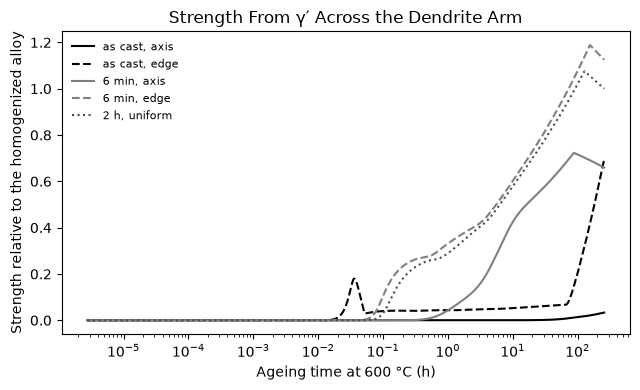

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 4.0))
for key, h in aged.items():
    grey, style = looks[key]
    label = f"{key[0]}, {key[1]}" if key[0] != "2 h" else "2 h, uniform"
    ax.semilogx(h.times[1:] / 3600, h.strength[1:] / reference,
                color=grey, linestyle=style, label=label)
ax.set_xlabel("Ageing time at 600 °C (h)")
ax.set_ylabel("Strength relative to the homogenized alloy")
ax.set_title("Strength From γ′ Across the Dendrite Arm")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()

In [8]:
# where the uniform alloy sits against the weak-pair limit of Ahmadi
# et al.: eq. 29 holds while 2 gamma_APB r_s / 2T <= 1/2 (Psi_c >= 120 deg)
sm = strengths["2 h", "axis"]
r_s, l_s = float(np.ravel(sm.rss)[-1]), float(np.ravel(sm.Ls)[-1])
G, b, nu = shear, dislocations.b, poisson
for name, log in (("ln(r0/ri) = 2 pi", 2 * np.pi),
                  ("r0 = Ls, ri = b", np.log(l_s / b))):
    T = G * b**2 / (4 * np.pi) * (1 + nu - 3 * nu) / (1 - nu) * log  # eq. 3
    print(f"{name:<18} 2 gamma r / 2T = {0.175 * r_s / T:.2f}")
print(f"absolute, homogenized alloy at 256 h: {reference / 1e9:.2f} GPa")

ln(r0/ri) = 2 pi   2 gamma r / 2T = 1.30
r0 = Ls, ri = b    2 gamma r / 2T = 2.04
absolute, homogenized alloy at 256 h: 1.69 GPa


Read the strength as a comparison across the arm, not as a prediction of the yield strength.
At the end of ageing the as-cast dendrite axis, which barely precipitates, gains only a small
fraction of what the homogenized alloy gains; elsewhere in the arm the gain lies within a factor
of two of it. That contrast between the lean core and the rest is the robust result.

The absolute values and the shapes of the curves are not. kawin's model gives the homogenized
alloy well over 1 GPa (printed above), far above the 1.0 GPa rise in microhardness that Sudbrack
et al. (2006) measured over 1024 h at this temperature. By the end of ageing the particles are
past the weak-pair regime of Ahmadi et al.'s eq. 29, which holds while the ratio printed above
stays below 0.5; it is 1.3 to 2 here. The as-cast arm edge, with 37 % γ′, keeps a small strength
for 100 h and then jumps, which reads as the model's choice between mechanisms at a fraction
this high rather than as physics. The elastic constants and APB energy are also those of binary
γ and γ′.

Where the arm froze rich in Al, γ′ forms early and in quantity, and the as-cast arm edge comes
close to its equilibrium fraction within a few hours. The lean dendrite axis of the as-cast arm
barely precipitates in 256 h, although equilibrium would put about 5 % γ′ there. Its driving
force for nucleation is 148 J/mol against 369 J/mol in the nominal alloy, and the nucleation
barrier scales with the inverse square of it. A 6 minute anneal at 1200 °C already narrows the
spread, and after 2 hours the arm ages as the nominal alloy does.

Classical nucleation theory carries the largest uncertainty here. For this alloy it predicts
nucleation earlier and denser than the atom probe measured (Sudbrack et al. 2006), so the
delay at the axis is a direction and an order of size rather than a time to trust.

## 5. Check: janus-kinetics and kawin on the same ageing

Both packages read the same database and mobilities, so they should agree on everything that
does not depend on their different precipitation models: the γ′ nucleus and its driving force,
and the interdiffusion matrix of γ. Their kinetics need not agree in detail, since janus-kinetics
follows Svoboda, Fischer, Fratzl and Kozeschnik (Mater. Sci. Eng. A 385 (2004) 166) and kawin the
Kampmann-Wagner numerical model with the growth law of Philippe and Voorhees (Acta Mater. 61
(2013) 4237).

In [9]:
from janus_kinetics.multicomponent_precipitation import (
    PrecipitateThermo,
    solve_multicomponent_precipitation,
)

x0 = np.append(alloy, 1 - sum(alloy))
mu = np.asarray(gamma.chemical_potentials(x0, 873.0), dtype=float)
nucleus, dg = PrecipitateThermo(db, "L12_FCC", comps).nucleus(mu, 873.0)
dg_k, nucleus_k = thermo.getDrivingForce(alloy, 873.0)
print(f"driving force: janus {dg:.2f}, kawin {float(dg_k):.2f} J/mol")
print("nucleus Al, Cr: janus", np.round(100 * nucleus[:2], 3),
      "kawin", np.round(100 * np.ravel(nucleus_k), 3))
d_janus = gamma.interdiffusion_matrix(alloy, 873.0)
d_kawin = thermo.getInterdiffusivity(alloy, 873.0)
print("largest difference in the interdiffusion matrix:",
      f"{np.max(np.abs(d_kawin / d_janus - 1)):.1e}")

driving force: janus 368.76, kawin 368.76 J/mol
nucleus Al, Cr: janus [16.373  8.246] kawin [16.373  8.246]
largest difference in the interdiffusion matrix: 6.7e-10


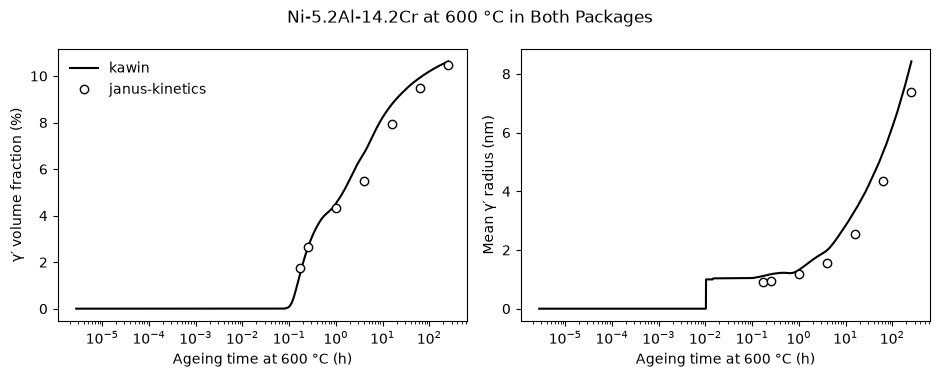

In [10]:
hours = np.array([0.167, 0.25, 1, 4, 16, 64, 256])
janus = solve_multicomponent_precipitation(
    gamma, PrecipitateThermo(db, "L12_FCC", comps), x0, 873.0,
    hours[-1] * 3600, settings, hours * 3600,
    precipitate_tracer=[2.7e-23, 1.4e-23, 2.7e-23])
k = aged["2 h", "axis"]  # the homogenized alloy is the nominal one

fig, (a, b) = plt.subplots(1, 2, figsize=(9.5, 3.8))
a.semilogx(k.times[1:] / 3600, 100 * k.volume_fraction[1:], "k-",
           label="kawin")
a.semilogx(hours, 100 * janus.volume_fraction, "ko", mfc="white",
           label="janus-kinetics")
b.semilogx(k.times[1:] / 3600, 1e9 * k.mean_radius[1:], "k-")
b.semilogx(hours, 1e9 * janus.mean_radius, "ko", mfc="white")
a.set_xlabel("Ageing time at 600 °C (h)")
a.set_ylabel("γ′ volume fraction (%)")
b.set_xlabel("Ageing time at 600 °C (h)")
b.set_ylabel("Mean γ′ radius (nm)")
a.legend(frameon=False)
fig.suptitle("Ni-5.2Al-14.2Cr at 600 °C in Both Packages")
fig.tight_layout()